# 📊 TickerMiner
Notebook de Analisis Exploratorio de Datos (EDA)

## Preliminares

In [8]:
import pandas as pd

from src.modeling import (
    cargar_datos_clean, filtrar_pares_restantes, separar_train_test,
    categorizar_en_cuantiles
    )
from src.transform import encontrar_columnas
from src.eda_utils import (
    mostrar_asimetrias, mostrar_missings, pintar_columna,
    top_correlaciones, pintar_violin_plots, top_correlaciones_objetivo
)

# Cargar fichero de precios
df_clean = cargar_datos_clean()

df_clean.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 931 entries, 2007-12-17 to 2026-11-02
Columns: 124 entries, EURUSD_intra_weekly to VIX_pct_chg_50d_yeo
dtypes: float64(124)
memory usage: 909.2 KB


In [9]:
# Missings
mostrar_missings(df_clean)

Series([], dtype: float64)

## Analisis de variables

In [10]:
# Descripcion de variables
columnas_clean = df_clean.columns.tolist()
cadena = "SPY_"
columnas = encontrar_columnas(columnas_target=columnas_clean, cadena=cadena)

df_clean[columnas].describe().T

,count,mean,std,min,25%,50%,75%,max
SPY_acceleration_zscore_lag1,931.0,-8.784417e-02,1.082559,-4.661541,-0.772979,-0.126563,0.546074,4.991397
SPY_return_zscore_lag1,931.0,1.090403e-01,1.077723,-7.730729,-0.431010,0.202159,0.759712,3.758263
SPY_return_skew_lag1,931.0,-3.528873e-01,0.546891,-2.992350,-0.794874,-0.249562,0.044189,0.866149
SPY_ret_diff_zscore_lag1,931.0,-5.601859e-03,1.076230,-2.989416,-0.749758,-0.144395,0.621700,4.563764
SPY_accel_diff_zscore_lag1,931.0,3.387691e-02,1.079649,-3.160562,-0.717730,-0.047564,0.669261,5.404879
SPY_vol_ratio_lag1,931.0,9.764867e-01,0.172604,0.456470,0.846543,1.004558,1.111002,1.266611
SPY_std_lag1_log,931.0,-3.898865e+00,0.358866,-4.921623,-4.133386,-3.916055,-3.661157,-2.986865
SPY_vol_directional_lag1_log,931.0,-1.836810e-01,0.366659,-1.877387,-0.424231,-0.211790,0.012736,1.779588
SPY_Volume_zscore_lag1_yeo,931.0,1.526408e-17,1.000537,-4.693651,-0.570351,-0.010394,0.604001,4.637788


In [11]:
# Asimetrias general
mostrar_asimetrias(df_clean)

VIX_level                           2.382774
USDCAD_std_lag1_log                 1.730749
EURUSD_return_skew_lag1             1.589679
USDCHF_std_lag1_log                 1.103859
Oil_vol_directional_lag1_log        0.971718
STLFSI_delta_50d                    0.953561
EURUSD_open_gap_zscore_yeo          0.812118
VIX_level_skew                      0.803235
GBPUSD_std_lag1_log                 0.794907
Real_yield_delta_50d                0.787467
EURUSD_gap_skew_lag1                0.749568
Oil_std_lag1_log                    0.726685
SPY_ret_diff_zscore_lag1            0.592632
AUDUSD_vol_directional_lag1_log     0.572392
SPY_accel_diff_zscore_lag1          0.549106
Oil_return_skew_lag1                0.532260
AUDUSD_sma15_pct_diff_sma50_lag1    0.497620
GBPUSD_vol_directional_lag1_log     0.434020
USDJPY_sma15_pct_diff_sma50_lag1    0.378803
AUDUSD_accel_diff_zscore_lag1       0.369585
USDJPY_gap_skew_lag1                0.351795
SPY_vol_directional_lag1_log        0.349884
GBPUSD_acc

In [19]:
# Asimetria por grupo
cadena = "_yield_spread_"
columnas = encontrar_columnas(columnas_target=columnas_clean, cadena=cadena)
mostrar_asimetrias(df_clean[columnas])

AUDUSD_yield_spread_zscore    0.217118
USDJPY_yield_spread_zscore    0.081796
EURUSD_yield_spread_zscore    0.059065
GBPUSD_yield_spread_zscore   -0.016033
USDCAD_yield_spread_zscore   -0.116163
USDCHF_yield_spread_zscore   -0.212616


Cont


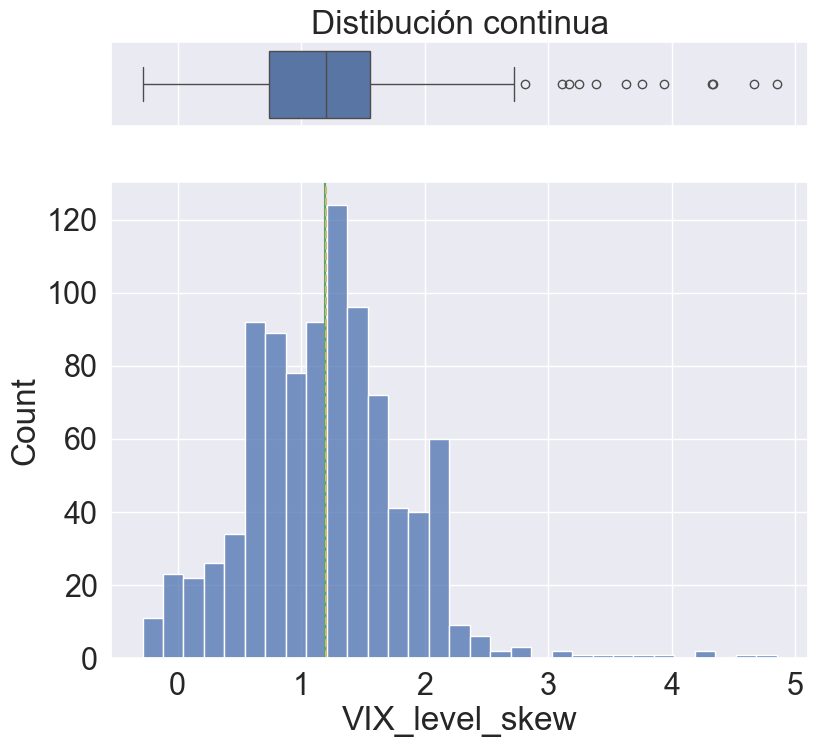

In [13]:
# Visualizar columna
col = 'VIX_level_skew'
pintar_columna(df_clean[col])

## Correlaciones

In [14]:
# Tabla de Correlaciones general
top_correlaciones(df=df_clean, top_n=30)

,Variable A,Variable B,correlation
350,USDJPY_accel_diff_zscore_lag1,USDJPY_ret_diff_zscore_lag1,0.906543
2079,Oil_accel_diff_zscore_lag1,Oil_ret_diff_zscore_lag1,0.894487
1710,Gold_accel_diff_zscore_lag1,Gold_ret_diff_zscore_lag1,0.894478
170,GBPUSD_accel_diff_zscore_lag1,GBPUSD_ret_diff_zscore_lag1,0.889202
594,USDCAD_accel_diff_zscore_lag1,USDCAD_ret_diff_zscore_lag1,0.885022
902,USDCHF_accel_diff_zscore_lag1,USDCHF_ret_diff_zscore_lag1,0.881811
2484,SPY_accel_diff_zscore_lag1,SPY_ret_diff_zscore_lag1,0.880163
1274,AUDUSD_accel_diff_zscore_lag1,AUDUSD_ret_diff_zscore_lag1,0.870579
54,EURUSD_accel_diff_zscore_lag1,EURUSD_ret_diff_zscore_lag1,0.869155
1415,AUDUSD_sma15_pct_diff_sma50_lag1,USDCAD_sma15_pct_diff_sma50_lag1,0.842330


In [15]:
# Correlaciones con la variable objetivo continua
simbolo_objetivo = 'EURUSD'
objetivo = f"{simbolo_objetivo}_intra_weekly"

top_correlaciones_objetivo(df=df_clean, target_col=objetivo)

,Variable,Correlación
0,GBPUSD_intra_weekly,0.643587
1,USDCHF_intra_weekly,-0.639030
2,AUDUSD_intra_weekly,0.469670
3,USDJPY_intra_weekly,-0.357603
4,USDCAD_intra_weekly,-0.348598
5,EURUSD_range10_position_lag1,-0.187176
6,USDCHF_return_zscore_lag1,0.170805
7,EURUSD_vol_directional_lag1_log,0.163777
8,USDCHF_range10_position_lag1,0.160841
9,DXY_pct_chg_50d,0.151558


## Analisis de label categorica

In [16]:
# Filtrar pares restantes
df_filtrado = filtrar_pares_restantes(df_clean,simbolo_objetivo)

# Separar datos de entrenamiento y test  
ultima_fecha = df_filtrado.index.max()
df_train, df_live = separar_train_test(df=df_filtrado, fecha=ultima_fecha)

# Se crea la variable categorica a partir del dataset de entrenamiento
# Variable objetivo: se crea variable categorica por cuantiles

objetivo_cat = f"{objetivo}_cat"

df_train, tabla_bins = categorizar_en_cuantiles(
    df_train, 
    columna=objetivo, 
    num_cuantiles=3, 
    quitar_original=True
    )


print(f"\n--- Rangos por Categoría para el ticker {simbolo_objetivo} ---")
print(tabla_bins)


--- Rangos por Categoría para el ticker EURUSD ---
   categoria  lim_inferior  lim_superior
0          1     -3.152512     -0.501504
1          2     -0.501504      0.454132
2          3      0.454132      3.688076


In [17]:
df_train[objetivo_cat].value_counts()

EURUSD_intra_weekly_cat
1    310
2    310
3    310
Name: count, dtype: int64



In [18]:
# Violin plot
# Identificar las variables numéricas excluyendo la variable objetivo
target_col = objetivo_cat
numeric_cols = df_train.select_dtypes(include=["number"]).columns.tolist()

# Asegurar que la columna objetivo no esté en la lista
numeric_cols = [col for col in numeric_cols if col != target_col]


pintar_violin_plots(
    df=df_train,
    numeric_cols=numeric_cols,
    target_col=target_col
)